# Preparação dos dados e modelo de risco municipal
## 1. Introdução
Vamos usar os indicadores de 2023 para estimar quais municípios correm maior risco de não atingir a meta de alfabetização em 2024.

Cada registro representa um município, uma rede e um ano. O alvo é `risco_meta`: 1 significa que o município não atingiu a meta; 0 significa que atingiu. Mantemos o foco municipal já adotado no projeto, pois a Gold não contém resultados individuais de alunos.

O PDF pede originalmente a classificação de alunos. Portanto, este modelo municipal não atende integralmente a esse objetivo. A análise usa dados históricos; ainda precisamos confirmar se os indicadores de 2023 já estavam publicados no momento da previsão.

## 2. Requisitos do desafio

Neste notebook, mantemos:

- Dados Gold municipais e informações do ano anterior para prever risco de não atingir a meta.
- Tratamento de números e categorias junto com o modelo em um pipeline.
- Municípios separados entre treino, validação e teste. O tratamento aprende apenas com os dados de treino de cada etapa.
- Um modelo de referência, regressão logística e Random Forest, com comparação e busca de parâmetros.
- Métricas, análise das variáveis importantes e uma lista de municípios com maior risco estimado.

## 4. Importando as bibliotecas

In [53]:
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import VarianceThreshold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay, brier_score_loss)
from sklearn.inspection import permutation_importance

SEMENTE = 42
LIMIAR = 0.5  # fixado previamente; não otimizado pelo teste
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', lambda valor: f'{valor:,.4f}')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'figure.dpi': 110})
versoes = {nome: version(nome) for nome in ['pandas', 'numpy', 'matplotlib',
    'seaborn', 'scikit-learn', 'nbformat', 'nbclient', 'ipykernel']}
display(pd.Series(versoes, name='versão executada'))

pandas           3.1.0
numpy            2.4.6
matplotlib      3.11.2
seaborn         0.13.2
scikit-learn     1.9.1
nbformat        5.11.1
nbclient        0.11.0
ipykernel        7.4.0
Name: versão executada, dtype: str

## 5. Carregando os dados
Vamos carregar os três arquivos da Gold. O modelo usa os dados municipais.

In [54]:
raiz = Path.cwd()
if raiz.name == 'notebooks':
    raiz = raiz.parent

pasta_gold = raiz / 'data' / 'gold'

municipios = pd.read_csv(pasta_gold / 'indicadores_municipio.csv')
ufs = pd.read_csv(pasta_gold / 'indicadores_uf.csv')
brasil = pd.read_csv(pasta_gold / 'indicadores_brasil.csv')

dados_gold = {
    'indicadores_municipio': municipios,
    'indicadores_uf': ufs,
    'indicadores_brasil': brasil
}


In [55]:
ufs.head(2)

,ano,sigla_uf,rede,taxa_oficial,media_portugues,percentual_participacao,meta_alfabetizacao_2024,meta_alfabetizacao_2025,meta_alfabetizacao_2026,meta_alfabetizacao_2027,meta_alfabetizacao_2028,meta_alfabetizacao_2029,meta_alfabetizacao_2030,meta_do_ano,diferenca_para_meta,situacao_meta,_data_criacao_gold
0,2023,AL,5,43.8800,729.7227,92.3600,49.7000,55.5000,61.1000,66.5000,71.5000,76.0000,80.0000,NaN,NaN,Sem meta,2026-11-03 01:04:36.097610
1,2023,AM,5,52.2000,736.4687,76.1400,56.8000,61.3000,65.6000,69.6000,73.4000,76.9000,80.0000,NaN,NaN,Sem meta,2026-11-03 01:04:36.097610


In [56]:
brasil.head(2)

,ano,rede,taxa_oficial,percentual_participacao,meta_alfabetizacao_2024,meta_alfabetizacao_2025,meta_alfabetizacao_2026,meta_alfabetizacao_2027,meta_alfabetizacao_2028,meta_alfabetizacao_2029,meta_alfabetizacao_2030,meta_do_ano,diferenca_para_meta,situacao_meta,_data_criacao_gold
0,2023,5,55.9000,86.0000,59.9000,63.7700,67.4700,70.9700,74.2300,77.2400,80.0000,NaN,NaN,Sem meta,2026-11-03 01:04:36.459787
1,2024,5,59.2000,87.3700,59.9000,63.7700,67.4700,70.9700,74.2300,77.2400,80.0000,59.9000,-0.7000,Não atingida,2026-11-03 01:04:36.459787


In [57]:
municipios.head(2)

,ano,id_municipio,rede,alunos_presentes,alunos_alfabetizados,media_proficiencia,taxa_microdados,taxa_oficial,media_portugues,nivel_alfabetizacao,percentual_participacao,meta_alfabetizacao_2024,meta_alfabetizacao_2025,meta_alfabetizacao_2026,meta_alfabetizacao_2027,meta_alfabetizacao_2028,meta_alfabetizacao_2029,meta_alfabetizacao_2030,meta_do_ano,diferenca_para_meta,situacao_meta,_data_criacao_gold
0,2023,1100015,3,227,153,759.9377,67.4000,64.5500,758.3304,3.0000,89.3700,67.0800,69.5100,71.8400,74.0600,76.1600,78.1400,80.0000,NaN,NaN,Sem meta,2026-11-03 01:04:32.066935
1,2023,1100023,3,1222,764,757.4660,62.5200,62.3000,757.0999,3.0000,89.7900,65.2200,68.0200,70.7100,73.2500,75.6500,77.9000,80.0000,NaN,NaN,Sem meta,2026-11-03 01:04:32.066935


In [58]:
municipios['nivel_alfabetizacao'].unique().tolist()

[3.0, 2.0, 5.0, 1.0, 4.0, 0.0, nan]

In [59]:
municipios.info()

<class 'pandas.DataFrame'>
RangeIndex: 10271 entries, 0 to 10270
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ano                      10271 non-null  int64  
 1   id_municipio             10271 non-null  int64  
 2   rede                     10271 non-null  int64  
 3   alunos_presentes         10271 non-null  int64  
 4   alunos_alfabetizados     10271 non-null  int64  
 5   media_proficiencia       10271 non-null  float64
 6   taxa_microdados          10271 non-null  float64
 7   taxa_oficial             10269 non-null  float64
 8   media_portugues          10269 non-null  float64
 9   nivel_alfabetizacao      9963 non-null   float64
 10  percentual_participacao  9963 non-null   float64
 11  meta_alfabetizacao_2024  9843 non-null   float64
 12  meta_alfabetizacao_2025  10031 non-null  float64
 13  meta_alfabetizacao_2026  10031 non-null  float64
 14  meta_alfabetizacao_2027  10031 no

In [ ]:

colunas_historicas = [
    'id_municipio',
    'ano',
    'taxa_oficial',
    'alunos_presentes',
    'percentual_participacao',
    'nivel_alfabetizacao',
    'media_proficiencia',
    'media_portugues',
    'rede'
]


historico = municipios.loc[
    municipios['ano'].eq(2023),
    colunas_historicas
].copy()

historico = historico.rename(
    columns={
        coluna: f'{coluna}_2023'
        for coluna in colunas_historicas
        if coluna not in ['id_municipio', 'rede']
    }
)

resultado = municipios.loc[
    municipios['ano'].eq(2024),
    [
        'id_municipio',
        'rede',
        'ano',
        'taxa_oficial',
        'meta_do_ano'
    ]
].copy()

resultado = resultado.rename(
    columns={
        'ano': 'ano_alvo',
        'taxa_oficial': 'taxa_2024',
        'meta_do_ano': 'meta_2024'
    }
)

painel = historico.merge(
    resultado,
    on=['id_municipio', 'rede'],
    how='inner',
    validate='one_to_one'
)


painel_completo = painel.dropna(
    subset=['taxa_2024', 'meta_2024']
).copy()

painel_completo['risco_meta'] = (
    painel_completo['taxa_2024'] < painel_completo['meta_2024']
).astype(int)


painel_completo = (
    painel_completo
    .sort_values(['id_municipio', 'rede'])
    .reset_index(drop=True)
)


assert not painel_completo.duplicated(
    subset=['id_municipio', 'rede']
).any(), 'Existem chaves duplicadas.'

assert painel_completo['ano_2023'].lt(
    painel_completo['ano_alvo']
).all()

assert painel_completo['risco_meta'].isin([0, 1]).all()


In [ ]:

display(
    painel_completo[
        [
            'id_municipio',
            'rede',
            'media_proficiencia_2023',
            'media_portugues_2023',
            'taxa_2024',
            'meta_2024',
            'risco_meta'
        ]
    ].head()
)

,id_municipio,rede,media_proficiencia_2023,media_portugues_2023,taxa_2024,meta_2024,risco_meta
0,1100015,3,759.9377,758.3304,67.7900,67.0800,0
1,1100023,3,757.4660,757.0999,65.6200,65.2200,0
2,1100031,3,767.6755,767.8763,75.8800,70.8500,0
3,1100049,3,756.0535,755.5645,65.8100,65.3900,0
4,1100056,3,745.4191,746.4629,66.8100,62.0900,0


In [ ]:


display(
    pd.Series({
        'municípios 2023': len(historico),
        'municípios 2024': len(resultado),
        'chaves comuns': len(painel),
        'comuns sem alvo excluídos': len(painel) - len(painel_completo),
        'amostra elegível': len(painel_completo),
        '2024 sem histórico': len(resultado) - len(painel),
        'cobertura elegível sobre 2024 (%)':
            100 * len(painel_completo) / len(resultado)
            if len(resultado) > 0 else 0
    }, name='cobertura')
)


municípios 2023                     4,822.0000
municípios 2024                     5,449.0000
chaves comuns                       4,774.0000
comuns sem alvo excluídos             163.0000
amostra elegível                    4,611.0000
2024 sem histórico                    675.0000
cobertura elegível sobre 2024 (%)      84.6210
Name: cobertura, dtype: float64

In [63]:
painel_completo.info()

<class 'pandas.DataFrame'>
RangeIndex: 4611 entries, 0 to 4610
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id_municipio                  4611 non-null   int64  
 1   ano_2023                      4611 non-null   int64  
 2   taxa_oficial_2023             4611 non-null   float64
 3   alunos_presentes_2023         4611 non-null   int64  
 4   percentual_participacao_2023  4611 non-null   float64
 5   nivel_alfabetizacao_2023      4611 non-null   float64
 6   media_proficiencia_2023       4611 non-null   float64
 7   media_portugues_2023          4611 non-null   float64
 8   rede                          4611 non-null   int64  
 9   ano_alvo                      4611 non-null   int64  
 10  taxa_2024                     4611 non-null   float64
 11  meta_2024                     4611 non-null   float64
 12  risco_meta                    4611 non-null   int64  
dtypes: float64(7),

In [64]:
indices = painel_completo.index.to_numpy()
indices_desenvolvimento, indices_teste = train_test_split(indices,
    test_size=0.20, random_state=SEMENTE, stratify=painel_completo.risco_meta)
indices_treino, indices_validacao = train_test_split(indices_desenvolvimento,
    test_size=0.25, random_state=SEMENTE,
    stratify=painel_completo.loc[indices_desenvolvimento, 'risco_meta'])
particoes = {'treino': indices_treino, 'validação': indices_validacao, 'teste': indices_teste}
for a, b in [('treino', 'validação'), ('treino', 'teste'), ('validação', 'teste')]:
    assert set(painel_completo.loc[particoes[a], 'id_municipio']).isdisjoint(
        painel_completo.loc[particoes[b], 'id_municipio'])
assert sum(map(len, particoes.values())) == len(painel_completo)
display(pd.DataFrame([{'partição': nome, 'n': len(idx),
    'classe 0': int(painel_completo.loc[idx, 'risco_meta'].eq(0).sum()),
    'classe 1': int(painel_completo.loc[idx, 'risco_meta'].eq(1).sum()),
    'risco (%)': painel_completo.loc[idx, 'risco_meta'].mean() * 100}
    for nome, idx in particoes.items()]))

,partição,n,classe 0,classe 1,risco (%)
0,treino,2766,1480,1286,46.4931
1,validação,922,493,429,46.5293
2,teste,923,494,429,46.4789


A tabela confere a quantidade de registros e a proporção das classes em cada conjunto. Não aplicamos técnicas para equilibrar as classes, pois não há um desequilíbrio grande. O teste continua reservado.

In [65]:
painel_completo.head(2)

,id_municipio,ano_2023,taxa_oficial_2023,alunos_presentes_2023,percentual_participacao_2023,nivel_alfabetizacao_2023,media_proficiencia_2023,media_portugues_2023,rede,ano_alvo,taxa_2024,meta_2024,risco_meta
0,1100015,2023,64.5500,227,89.3700,3.0000,759.9377,758.3304,3,2024,67.7900,67.0800,0
1,1100023,2023,62.3000,1222,89.7900,3.0000,757.4660,757.0999,3,2024,65.6200,65.2200,0


In [66]:
painel_completo.columns

Index(['id_municipio', 'ano_2023', 'taxa_oficial_2023',
       'alunos_presentes_2023', 'percentual_participacao_2023',
       'nivel_alfabetizacao_2023', 'media_proficiencia_2023',
       'media_portugues_2023', 'rede', 'ano_alvo', 'taxa_2024', 'meta_2024',
       'risco_meta'],
      dtype='str')

In [ ]:


colunas_numericas = [
    'taxa_oficial_2023',
    'alunos_presentes_2023',
    'percentual_participacao_2023',
    'nivel_alfabetizacao_2023',
    'media_proficiencia_2023',
    'media_portugues_2023'
]


colunas_categoricas = [
    'rede'
]


coluna_alvo = 'risco_meta'


features = colunas_numericas + colunas_categoricas

In [ ]:
X = painel_completo[features].copy()
y = painel_completo[coluna_alvo].copy()

In [69]:
print('Variáveis numéricas:', len(colunas_numericas))
print('Variáveis categóricas:', len(colunas_categoricas))
print('Total de features:', len(features))
print('Dimensão X:', X.shape)
print('Dimensão y:', y.shape)

Variáveis numéricas: 6
Variáveis categóricas: 1
Total de features: 7
Dimensão X: (4611, 7)
Dimensão y: (4611,)


In [ ]:
X_treino = X.loc[indices_treino]
X_validacao = X.loc[indices_validacao]
X_teste = X.loc[indices_teste]

y_treino = y.loc[indices_treino]
y_validacao = y.loc[indices_validacao]
y_teste = y.loc[indices_teste]

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


def criar_preprocessador():

    numerico = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorico = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

    return ColumnTransformer([
        ('num', numerico, colunas_numericas),
        ('cat', categorico, colunas_categoricas)
    ])

In [ ]:

pipeline_base = Pipeline([
    ('preprocessor', criar_preprocessador()),
    ('model', LogisticRegression(
        max_iter=600,
        class_weight='balanced',
        random_state=SEMENTE
    ))
])
pipeline_rf = Pipeline([
    ('preprocessor', criar_preprocessador()),
    ('model', RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=SEMENTE,
        n_jobs=-1
    ))
])


# MODELO 3 - XGBOOST


pipeline_xgb = Pipeline([
    ('preprocessor', criar_preprocessador()),
    ('model', XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=SEMENTE,
        n_jobs=-1
    ))
])

In [ ]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ORGANIZAR OS MODELOS


modelos = {
    'Regressão Logística': pipeline_base,
    'Random Forest': pipeline_rf,
    'XGBoost': pipeline_xgb
}

resultados = []

# TREINAMENTO E AVALIAÇÃO


for nome, modelo in modelos.items():

    modelo.fit(X_treino, y_treino)

    y_pred = modelo.predict(X_validacao)
    y_proba = modelo.predict_proba(X_validacao)[:, 1]

    resultados.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_validacao, y_pred),
        'Precisão': precision_score(
            y_validacao, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_validacao, y_pred, zero_division=0
        ),
        'F1-Score': f1_score(
            y_validacao, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_validacao, y_proba)
    })


# COMPARAÇÃO DOS MODELOS


df_resultados = pd.DataFrame(resultados)

display(
    df_resultados.sort_values(
        by='Recall',
        ascending=False
    ).round(4)
)

,Modelo,Acurácia,Precisão,Recall,F1-Score,ROC-AUC
1,Random Forest,0.6497,0.6238,0.6224,0.6231,0.7111
0,Regressão Logística,0.6356,0.6094,0.6037,0.6066,0.6803
2,XGBoost,0.6453,0.6294,0.5781,0.6027,0.7029


In [ ]:

# SELECIONAR O MELHOR MODELO

melhor_nome = df_resultados.sort_values(
    by='Recall',
    ascending=False
).iloc[0]['Modelo']

melhor_modelo = modelos[melhor_nome]

print(f'Melhor modelo: {melhor_nome}')

Melhor modelo: Random Forest


In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline


grupos_busca = painel_completo.loc[
    X_treino.index, 'id_municipio'
]


pipeline_rf = Pipeline([
    ('preprocessor', criar_preprocessador()),
    ('model', RandomForestClassifier(
        class_weight='balanced_subsample',
        n_jobs=-1,
        random_state=SEMENTE
    ))
])

espaco_busca = {
    'model__n_estimators': [80, 120, 160],
    'model__max_depth': [8, 10, 14, None],
    'model__min_samples_leaf': [15, 25, 40],
    'model__max_features': ['sqrt', 0.7]
}



validacao_cruzada = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEMENTE
)


busca_rf = RandomizedSearchCV(
    estimator=pipeline_rf,
    param_distributions=espaco_busca,
    n_iter=4,
    scoring='roc_auc',
    cv=validacao_cruzada,
    n_jobs=1,
    random_state=SEMENTE,
    return_train_score=True,
    refit=True,
    verbose=1
)


# TREINAMENTO


busca_rf.fit(
    X_treino,
    y_treino,
    groups=grupos_busca
)


#  RESULTADOS


print(f'Melhor ROC-AUC médio: {busca_rf.best_score_:.4f}')

print('\nMelhores hiperparâmetros:')
print(busca_rf.best_params_)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Melhor ROC-AUC médio: 0.6761

Melhores hiperparâmetros:
{'model__n_estimators': 80, 'model__min_samples_leaf': 15, 'model__max_features': 'sqrt', 'model__max_depth': 8}


In [ ]:
# MODELO RANDOM FOREST OTIMIZADO


pipeline_rf = Pipeline([
    ('preprocessor', criar_preprocessador()),
    ('model', RandomForestClassifier(
        n_estimators=80,
        max_depth=8,
        min_samples_leaf=15,
        max_features='sqrt',
        class_weight='balanced_subsample',
        random_state=SEMENTE,
        n_jobs=-1
    ))
])

pipeline_rf

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

In [ ]:
# TREINAMENTO RANDOM FOREST

pipeline_rf.fit(X_treino, y_treino)

# Previsões na validação
y_pred_rf = pipeline_rf.predict(X_validacao)

# Probabilidades da classe 1
y_proba_rf = pipeline_rf.predict_proba(X_validacao)[:, 1]

In [78]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

metricas_rf = {
    'Acurácia': accuracy_score(y_validacao, y_pred_rf),
    'Precisão': precision_score(y_validacao, y_pred_rf, zero_division=0),
    'Recall': recall_score(y_validacao, y_pred_rf, zero_division=0),
    'F1-Score': f1_score(y_validacao, y_pred_rf, zero_division=0),
    'ROC-AUC': roc_auc_score(y_validacao, y_proba_rf)
}

display(
    pd.DataFrame(
        metricas_rf.items(),
        columns=['Métrica', 'Resultado']
    ).round(4)
)

,Métrica,Resultado
0,Acurácia,0.6562
1,Precisão,0.6321
2,Recall,0.6247
3,F1-Score,0.6284
4,ROC-AUC,0.7056


### Matriz de confusão e curva ROC na validação

Os gráficos avaliam o Random Forest ajustado sem log. A matriz usa as classes previstas pelo modelo no limiar padrão e mostra os acertos e erros para a classe de risco (1). A curva ROC usa as probabilidades da classe 1 e mostra como a taxa de verdadeiros positivos varia com a taxa de falsos positivos ao mudar o limiar.

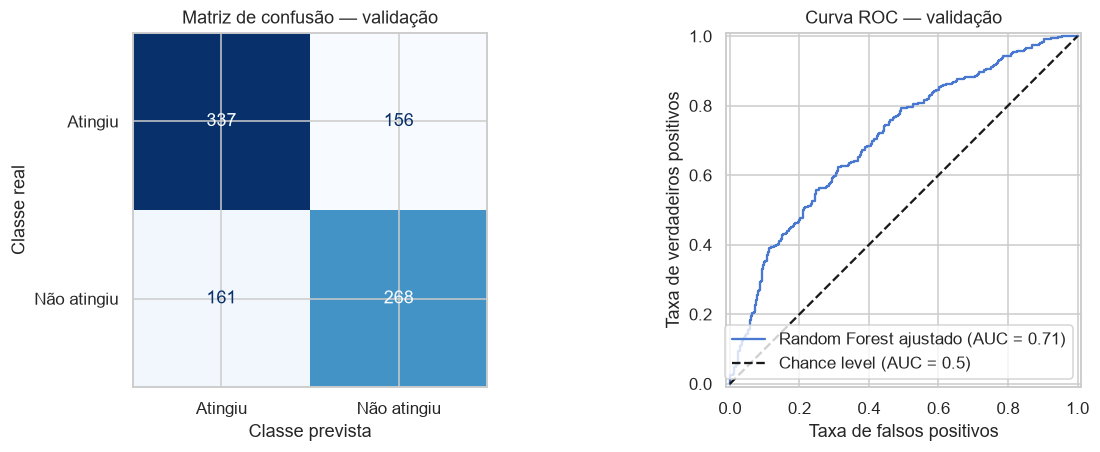

In [79]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, eixos = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')

ConfusionMatrixDisplay.from_predictions(
    y_validacao, y_pred_rf, labels=[0, 1],
    display_labels=['Atingiu', 'Não atingiu'],
    cmap='Blues', colorbar=False, ax=eixos[0]
)
eixos[0].set(title='Matriz de confusão — validação', xlabel='Classe prevista', ylabel='Classe real')

RocCurveDisplay.from_predictions(
    y_validacao, y_proba_rf, pos_label=1,
    name='Random Forest ajustado', plot_chance_level=True, ax=eixos[1]
)
eixos[1].set(title='Curva ROC — validação',
             xlabel='Taxa de falsos positivos', ylabel='Taxa de verdadeiros positivos')
plt.show()

### Random Forest com transformação logarítmica

In [ ]:
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier


colunas_log = [
    'alunos_presentes_2023'
]


colunas_numericas_sem_log = [
    coluna
    for coluna in colunas_numericas
    if coluna not in colunas_log
]


preprocessador_log = ColumnTransformer(
    transformers=[
        (
            'num_log',
            Pipeline([
                ('imputer', SimpleImputer(strategy='median')),
                ('log', FunctionTransformer(np.log1p))
            ]),
            colunas_log
        ),
        (
            'num',
            SimpleImputer(strategy='median'),
            colunas_numericas_sem_log
        ),
        (
            'cat',
            Pipeline([
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))
            ]),
            colunas_categoricas
        )
    ]
)


pipeline_rf_log = Pipeline([
    ('preprocessor', preprocessador_log),
    ('model', RandomForestClassifier(
        n_estimators=80,
        max_depth=8,
        min_samples_leaf=15,
        max_features='sqrt',
        class_weight='balanced_subsample',
        random_state=SEMENTE,
        n_jobs=-1
    ))
])

pipeline_rf_log

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_log', ...), ('num', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

pipeline_rf_log.fit(X_treino, y_treino)

y_pred_log = pipeline_rf_log.predict(X_validacao)

y_proba_log = pipeline_rf_log.predict_proba(
    X_validacao
)[:, 1]

metricas_log = {
    'Acurácia': accuracy_score(y_validacao, y_pred_log),
    'Precisão': precision_score(
        y_validacao, y_pred_log, zero_division=0
    ),
    'Recall': recall_score(
        y_validacao, y_pred_log, zero_division=0
    ),
    'F1-Score': f1_score(
        y_validacao, y_pred_log, zero_division=0
    ),
    'ROC-AUC': roc_auc_score(y_validacao, y_proba_log)
}

display(
    pd.DataFrame(
        metricas_log.items(),
        columns=['Métrica', 'Resultado']
    ).round(4)
)

,Métrica,Resultado
0,Acurácia,0.6540
1,Precisão,0.6285
2,Recall,0.6270
3,F1-Score,0.6278
4,ROC-AUC,0.7056


In [ ]:

comparacao = pd.DataFrame({
    'Random Forest Original': metricas_rf,
    'Random Forest com Log': metricas_log
})

comparacao['Diferença'] = (
    comparacao['Random Forest com Log']
    - comparacao['Random Forest Original']
)

display(comparacao.round(4))

,Random Forest Original,Random Forest com Log,Diferença
Acurácia,0.6562,0.6540,-0.0022
Precisão,0.6321,0.6285,-0.0036
Recall,0.6247,0.6270,0.0023
F1-Score,0.6284,0.6278,-0.0006
ROC-AUC,0.7056,0.7056,0.0000


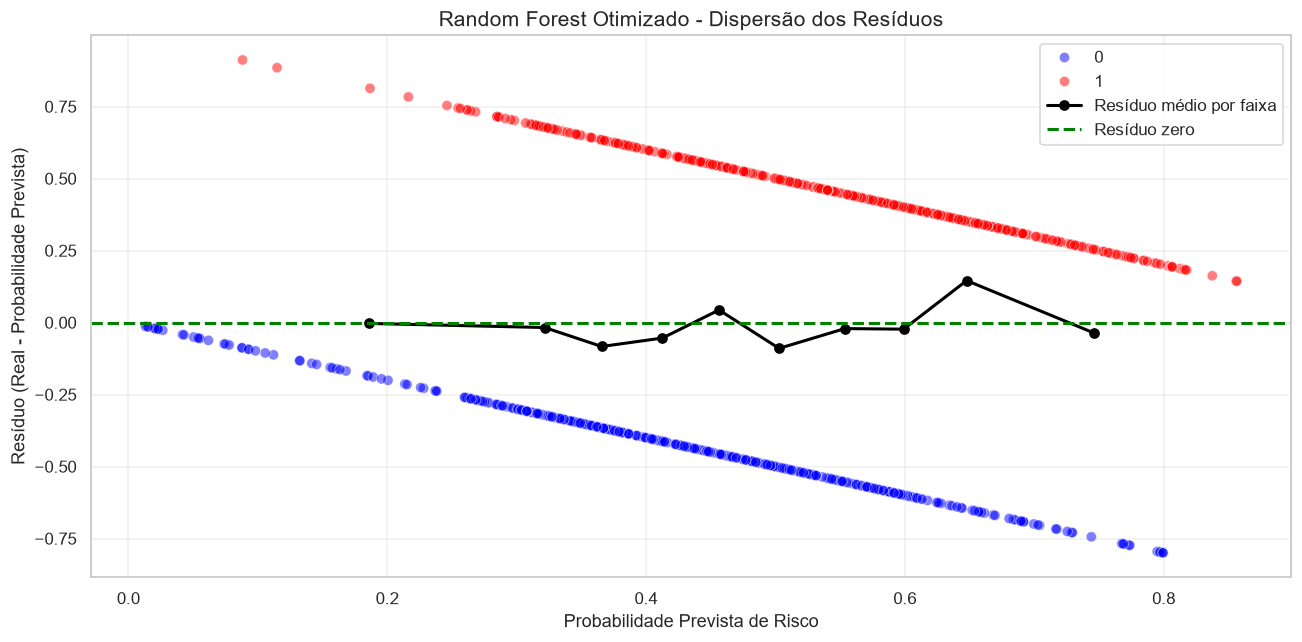

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

y_proba_rf = pipeline_rf.predict_proba(X_validacao)[:, 1]

df_residuos = pd.DataFrame({
    'probabilidade_prevista': y_proba_rf,
    'valor_real': y_validacao.to_numpy()
})

df_residuos['residuo'] = (
    df_residuos['valor_real']
    - df_residuos['probabilidade_prevista']
)

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df_residuos,
    x='probabilidade_prevista',
    y='residuo',
    hue='valor_real',
    palette={0: 'blue', 1: 'red'},
    alpha=0.5,
    s=45
)

# Resíduo médio em faixas com quantidades semelhantes de municípios.
faixas_probabilidade = pd.qcut(df_residuos['probabilidade_prevista'], 10, duplicates='drop')
tendencia = df_residuos.groupby(faixas_probabilidade, observed=True)[
    ['probabilidade_prevista', 'residuo']
].mean()
plt.plot(tendencia['probabilidade_prevista'], tendencia['residuo'],
         color='black', marker='o', linewidth=2, label='Resíduo médio por faixa')

# Linha de referência
plt.axhline(
    y=0,
    color='green',
    linestyle='--',
    linewidth=2,
    label='Resíduo zero'
)

plt.title(
    'Random Forest Otimizado - Dispersão dos Resíduos',
    fontsize=14
)

plt.xlabel('Probabilidade Prevista de Risco')
plt.ylabel('Resíduo (Real - Probabilidade Prevista)')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Como interpretar o gráfico de resíduos

O resíduo é a classe observada (0 ou 1) menos a probabilidade prevista de não atingir a meta. Um ponto da classe 1 muito acima de zero representa um município que ficou abaixo da meta, mas recebeu uma estimativa de risco baixa. Um ponto da classe 0 muito abaixo de zero representa um município que atingiu a meta, mas recebeu uma estimativa de risco alta.

As duas diagonais são esperadas: para a classe 1, o resíduo é `1 − probabilidade`; para a classe 0, é `−probabilidade`. Para investigar um padrão, observe a linha preta. Em cada faixa, ela representa a proporção observada de municípios que ficaram abaixo da meta menos a probabilidade média prevista:

- **Acima de zero:** o modelo subestimou o risco naquela faixa.
- **Abaixo de zero:** o modelo superestimou o risco naquela faixa.
- **Perto de zero:** a frequência observada e a probabilidade média prevista ficaram próximas.

Várias faixas consecutivas do mesmo lado de zero sugerem um desvio sistemático de calibração na validação. Para identificar erros de classificação no limiar de 50%, procure pontos da classe 1 à esquerda de 0,50 (falsos negativos) e pontos da classe 0 à direita de 0,50 (falsos positivos).

## Interpretando o Random Forest com SHAP

Seguindo os exemplos da Aula 3 (slides 33, 37, 38 e 50), usamos o `TreeExplainer` para explicar a probabilidade estimada da classe 1 (não atingir a meta). A análise usa os 922 registros de validação e o Random Forest ajustado sem log, selecionado na conclusão.

A importância global é a média do valor absoluto das contribuições. No gráfico de dispersão, cada ponto é um município: valores SHAP positivos aumentam a probabilidade estimada e valores negativos a reduzem em relação ao valor de referência do modelo. A cor representa o valor da variável após o pré-processamento. Indicadores correlacionados podem compartilhar importância. As contribuições descrevem o comportamento do modelo e não demonstram causalidade.

d:\Downloads\Tech Challenge - Fase 3\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Média de |SHAP|
percentual_participacao_2023,0.0700
taxa_oficial_2023,0.0447
media_proficiencia_2023,0.0289
alunos_presentes_2023,0.0281
media_portugues_2023,0.0265
nivel_alfabetizacao_2023,0.0219
rede_3,0.0000


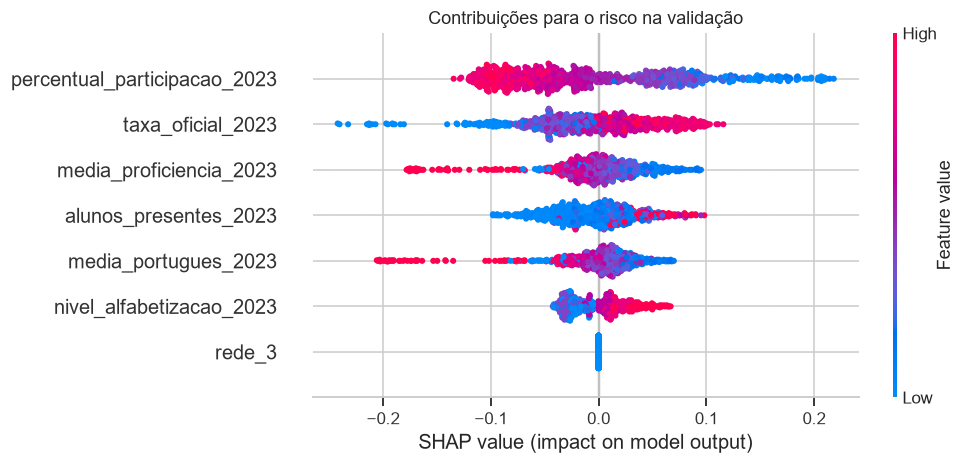

In [84]:
import shap

preprocessador_rf = pipeline_rf.named_steps['preprocessor']
floresta = pipeline_rf.named_steps['model']
X_shap = pd.DataFrame(
    preprocessador_rf.transform(X_validacao),
    columns=preprocessador_rf.get_feature_names_out(),
    index=X_validacao.index
)
X_shap.columns = X_shap.columns.str.split('__', n=1).str[-1]

classe_risco = floresta.classes_.tolist().index(1)
explicador = shap.TreeExplainer(floresta, feature_perturbation='tree_path_dependent')
shap_risco = explicador(X_shap)[:, :, classe_risco]

prob_risco = pipeline_rf.predict_proba(X_validacao)[:, classe_risco]
np.testing.assert_allclose(
    shap_risco.base_values + shap_risco.values.sum(axis=1),
    prob_risco,
    atol=1e-6
)

importancia_shap = pd.Series(
    np.abs(shap_risco.values).mean(axis=0),
    index=X_shap.columns,
    name='Média de |SHAP|'
).sort_values(ascending=False)
display(importancia_shap.to_frame())

shap.plots.beeswarm(shap_risco, show=False)
plt.title('Contribuições para o risco na validação')
plt.show()

### Explicação de um município

O gráfico em cascata mostra o município com a maior probabilidade de risco estimada na validação. Partindo do valor de referência, somamos as contribuições de cada variável até chegar à probabilidade estimada para o município.

Município 3300456 | Probabilidade estimada de risco: 85.7%


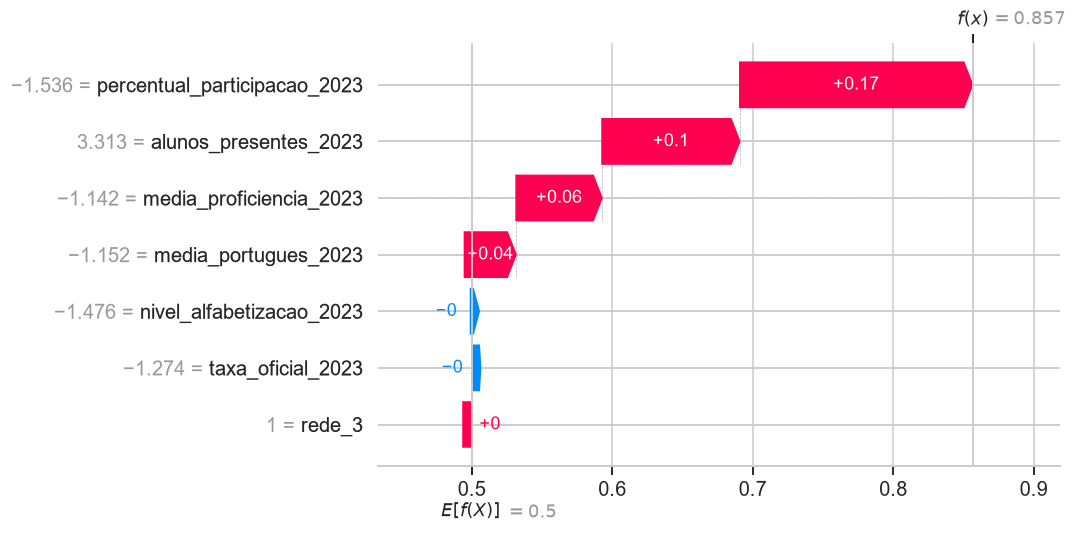

In [85]:
posicao = int(np.argmax(prob_risco))
indice = X_validacao.index[posicao]
municipio = painel_completo.loc[indice, 'id_municipio']
print(f'Município {municipio} | Probabilidade estimada de risco: {prob_risco[posicao]:.1%}')
shap.plots.waterfall(shap_risco[posicao], show=False)
plt.show()

## Exportando o pipeline treinado

Este arquivo contém o Random Forest ajustado sem log, treinado na partição de treino, com o pré-processamento já ajustado. O formato segue o artefato do notebook 03 e usa um nome próprio para distinguir os dois treinamentos. Carregue apenas arquivos de origem confiável.

In [86]:
import joblib

artefato_rf = {
    'pipeline': pipeline_rf,
    'features': features,
    'limiar': 0.50,
    'ano_historico_treino': 2023,
    'ano_alvo_treino': 2024,
    'redes_treino': sorted(X_treino['rede'].unique().tolist()),
    'versoes': {nome: version(nome) for nome in ['scikit-learn', 'numpy', 'pandas', 'joblib']},
}

caminho_rf = raiz / 'modelos' / 'risco_alfabetizacao.joblib'
caminho_rf.parent.mkdir(exist_ok=True)
temporario_rf = caminho_rf.with_suffix('.tmp')
joblib.dump(artefato_rf, temporario_rf, compress=3)

recarregado_rf = joblib.load(temporario_rf)
np.testing.assert_allclose(
    recarregado_rf['pipeline'].predict_proba(X_validacao)[:, 1],
    y_proba_rf
)
temporario_rf.replace(caminho_rf)
print(f'Pipeline salvo em {caminho_rf.relative_to(raiz)}')

Pipeline salvo em modelos\risco_alfabetizacao.joblib


## Conclusão — Seleção do Modelo de Machine Learning

O projeto teve como objetivo desenvolver um modelo de classificação binária para identificar municípios com risco de não atingir a meta de alfabetização, utilizando indicadores educacionais históricos de 2023 para prever os resultados de 2024.

Foram consideradas três abordagens de Machine Learning: **Regressão Logística (Baseline), Random Forest Classifier e XGBoost Classifier**. Os modelos foram estruturados com pipelines de pré-processamento, incluindo tratamento de valores ausentes, transformação de variáveis categóricas e preparação das variáveis numéricas.

Os dados foram divididos em 60% para treinamento, 20% para validação e 20% para teste. Para a otimização dos hiperparâmetros do Random Forest, foi utilizado o `RandomizedSearchCV` com validação cruzada `StratifiedGroupKFold`, considerando o município como grupo.

### Modelo selecionado: Random Forest Classifier

O **Random Forest Classifier foi selecionado como modelo final desta etapa**, considerando os resultados obtidos após a otimização dos hiperparâmetros e sua avaliação no conjunto de validação.

**Resultados do Random Forest otimizado:**

| Métrica | Resultado |
|---|---:|
| Acurácia | 0,6562 |
| Precisão | 0,6321 |
| Recall | 0,6247 |
| F1-Score | 0,6284 |
| ROC-AUC | 0,7056 |

O processo de otimização apresentou ROC-AUC médio de **0,6761 na validação cruzada**, enquanto a avaliação no conjunto de validação separado alcançou **0,7056**.

Os melhores hiperparâmetros identificados foram:

- `n_estimators = 80`
- `max_depth = 8`
- `min_samples_leaf = 15`
- `max_features = 'sqrt'`
- `class_weight = 'balanced_subsample'`

### Justificativa da escolha

A escolha do Random Forest foi fundamentada nos seguintes aspectos:

1. **Capacidade de identificar relações não lineares:** o algoritmo permite representar interações complexas entre indicadores de alfabetização, participação escolar e proficiência.
2. **Desempenho discriminatório:** o ROC-AUC de 0,7056 demonstra capacidade de distinguir municípios que atingiram e não atingiram a meta superior à classificação aleatória.
3. **Otimização de hiperparâmetros:** a aplicação do `RandomizedSearchCV` permitiu selecionar uma configuração com controle da complexidade das árvores, contribuindo para reduzir o risco de overfitting.
4. **Tratamento do desbalanceamento:** o parâmetro `class_weight='balanced_subsample'` permite ajustar os pesos das classes durante o treinamento.
5. **Aplicabilidade ao problema:** o modelo permite estimar a probabilidade de um município não atingir a meta, oferecendo informações para análises e priorização de acompanhamento educacional.

### Considerações finais

O Random Forest apresentou resultados promissores, embora ainda exista espaço para melhorar a identificação dos municípios que não atingem suas metas. O Recall de 0,6247 indica que aproximadamente **62,47% dos municípios da classe de risco foram corretamente identificados** na validação.

Dessa forma, o **Random Forest otimizado foi definido como o modelo selecionado para continuidade do projeto**.

Entretanto, essa escolha é preliminar: os resultados individuais da Regressão Logística e do XGBoost não foram apresentados nesta análise, portanto ainda não é possível afirmar que o Random Forest foi estatisticamente superior aos demais modelos.

Como próxima etapa, recomenda-se realizar a avaliação final no conjunto de teste reservado, além de comparar os resultados dos três algoritmos sob as mesmas condições. Isso permitirá confirmar a capacidade de generalização e fundamentar a escolha definitiva do modelo.